# Tool Use

## Introduction

**Tool use** allows Claude to interact with external systems such as databases,
APIs, search services, and business logic.

In this notebook, we build a **small customer-support assistant with tools** for:

- finding a customer
- retrieving orders
- checking an order
- canceling an eligible order

We will start with a single tool call and gradually build the complete
tool-use loop that allows Claude to decide when a tool is needed, execute it
through our application, and use the result to produce a final response.  

By the end of this notebook, you will be able to:

- define tools using an input schema
- provide tools to Claude through the Messages API
- inspect a tool-use response
- execute a requested tool in Python
- return the result to Claude with `tool_result`
- build a basic tool-use loop
- handle multiple tool calls
- extend an assistant with additional tools

##  Setup 

The following cells initialize the Anthropic client and select the model
used throughout this notebook.

In [1]:
# Import the Anthropic SDK client.
from anthropic import Anthropic

### Load credentials  
  
This repository uses environment variables to keep the Anthropic API key separate from the code. The provided helper function (`helper.py`) loads the variables from the local `.env` file (see `.env_example` file). 

In [2]:
# Load environment variables such as ANTHROPIC_API_KEY
from helper import load_env
load_env()

In [3]:
# Example model configuration.
MODEL_NAME="claude-sonnet-5"  

# Initialize the Anthropic client
client = Anthropic()

##  How Tool Use Works

Tool use lets Claude interact with external systems through your application. Instead of guessing, Claude can decide when it needs real data or an action—such as looking up a customer, checking an order, or canceling a purchase.  

Your application provides a list of tools, each with a name, description, and input schema. Claude decides whether a tool is needed, sends a structured request, and your app executes the corresponding function. The result is returned to Claude so it can continue the conversation with grounded information.  

### The Conceptual Flow

At a high level, tool use follows this pattern:

```text
User
  ↓
Claude
  ↓
Tool request
  ↓
Your application
  ↓
Tool execution
  ↓
Tool result
  ↓
Claude
  ↓
Final response
```

There are three main components:

1. **Claude** — determines whether a tool is needed and generates a structured tool request.
2. **Your application** — receives the request and executes the corresponding function.
3. **The tool** — performs the actual operation, such as looking up a customer, retrieving an order, or cancelling an order.

**Example:** A customer asks "What orders do I have?" Claude determines it needs to query the database. Rather than inventing an answer, it requests the `get_customer_orders tool`. Your app executes it and returns the real data. Claude then uses that to answer accurately.

**Key idea:** Claude does not execute your Python functions directly. It requests a tool; your application is responsible for running it.

### Tool Use Flow  

Now that you understand the conceptual pattern, let's see how it works in practice using the Messages API.

Tool use is implemented as an iterative message loop. Here's how it flows:

#### The Message Loop

The conceptual flow becomes an iterative message exchange when implemented through the Messages API.

The basic loop is:

```text
1. User sends a request
        ↓
2. Application sends the request and available tools to Claude
        ↓
3. Claude responds
        ↓
4. Application checks the response
        ↓
   ┌───────────────────────────────┐
   │                               │
   │  Tool requested?              │
   │                               │
   └───────────────┬───────────────┘
                   │
             Yes   │   No
              ↓    │    ↓
       Execute tool │  Return final
              ↓     │  response
       Send result │
              ↓     │
       Call Claude again
              │
              └───────────────→
```

The application uses the response's `stop_reason` to determine what happens next:

| `stop_reason` | Meaning                                        |
| ------------- | ---------------------------------------------- |
| `tool_use`    | Claude is requesting one or more tools.        |
| `end_turn`    | Claude has finished and produced its response. |


#### Step-by-step execution

When Claude requests a tool, the response contains a `tool_use` content block. This block identifies the tool and provides the input arguments.

A simplified example looks like:

```python
{
    "type": "tool_use",
    "id": "toolu_123",
    "name": "get_user",
    "input": {
        "key": "email",
        "value": "alex@example.com"
    }
}
```

Your application then uses the tool name and input to execute the corresponding Python function:

```python
tool_result = process_tool_call(
    tool_name=tool_use.name,
    tool_input=tool_use.input
)
```

The application sends the result back to Claude as a `tool_result`:

```python
{
    "type": "tool_result",
    "tool_use_id": tool_use.id,
    "content": str(tool_result)
}
```

The `tool_use_id` connects the result to the specific tool request that produced it.

Claude can then continue the conversation using the tool result. If another tool is needed, the application repeats the same process. Otherwise, Claude returns the final response.


#### The complete flow  

The complete pattern is therefore:

```text
User request
    ↓
Claude receives tools
    ↓
Claude returns tool_use
    ↓
Application executes the function
    ↓
Application returns tool_result
    ↓
Claude processes the result
    ↓
    ┌─────────────────────┐
    │ Another tool needed?│
    └──────────┬──────────┘
               │
        Yes ───┘ ──→ tool_use
               │
        No
               ↓
        Final response
```

 **Key idea:** Tool use is an iterative message loop. Claude requests tools, your application executes them, and the results are returned to Claude until Claude can produce the final response.


## Our Customer-Support Example  

To make tool use concrete, we will build a small customer-support assistant.

The assistant will be able to:  

- find a customer  
- retrieve a customer's orders  
- look up an individual order  
- cancel an eligible order  

Instead of connecting to a real database or external API, we will use a small in-memory database implemented in Python.

This lets us focus on the tool-use workflow without introducing additional infrastructure.

### The Fake Database  

Our fake database contains two types of records:

- Customers records — basic customer information
- Orders records — orders associated with a customer

Customers can be identified by email, phone number, or username. Orders are linked to customers through `customer_id`.

This lets us simulate a real customer-support backend without requiring
a database or external API.



In [4]:
class FakeDatabase:
    def __init__(self):
        self.customers = [
            {"id": "1213210", "name": "John Doe", "email": "john@gmail.com", "phone": "123-456-7890", "username": "johndoe"},
            {"id": "2837622", "name": "Priya Patel", "email": "priya@candy.com", "phone": "987-654-3210", "username": "priya123"},
            {"id": "3924156", "name": "Liam Nguyen", "email": "lnguyen@yahoo.com", "phone": "555-123-4567", "username": "liamn"},
            {"id": "4782901", "name": "Aaliyah Davis", "email": "aaliyahd@hotmail.com", "phone": "111-222-3333", "username": "adavis"},
            {"id": "5190753", "name": "Hiroshi Nakamura", "email": "hiroshi@gmail.com", "phone": "444-555-6666", "username": "hiroshin"},
            {"id": "6824095", "name": "Fatima Ahmed", "email": "fatimaa@outlook.com", "phone": "777-888-9999", "username": "fatimaahmed"},
            {"id": "7135680", "name": "Alejandro Rodriguez", "email": "arodriguez@protonmail.com", "phone": "222-333-4444", "username": "alexr"},
            {"id": "8259147", "name": "Megan Anderson", "email": "megana@gmail.com", "phone": "666-777-8888", "username": "manderson"},
            {"id": "9603481", "name": "Kwame Osei", "email": "kwameo@yahoo.com", "phone": "999-000-1111", "username": "kwameo"},
            {"id": "1057426", "name": "Mei Lin", "email": "meilin@gmail.com", "phone": "333-444-5555", "username": "mlin"}
        ]

        self.orders = [
            {"id": "24601", "customer_id": "1213210", "product": "Wireless Headphones", "quantity": 1, "price": 79.99, "status": "Shipped"},
            {"id": "13579", "customer_id": "1213210", "product": "Smartphone Case", "quantity": 2, "price": 19.99, "status": "Processing"},
            #{"id": "97531", "customer_id": "2837622", "product": "Bluetooth Speaker", "quantity": 1, "price": "49.99", "status": "Shipped"}, 
            {"id": "97531", "customer_id": "2837622", "product": "Bluetooth Speaker", "quantity": 1, "price": 49.99, "status": "Shipped"}, 
            {"id": "86420", "customer_id": "3924156", "product": "Fitness Tracker", "quantity": 1, "price": 129.99, "status": "Delivered"},
            {"id": "54321", "customer_id": "4782901", "product": "Laptop Sleeve", "quantity": 3, "price": 24.99, "status": "Shipped"},
            {"id": "19283", "customer_id": "5190753", "product": "Wireless Mouse", "quantity": 1, "price": 34.99, "status": "Processing"},
            {"id": "74651", "customer_id": "6824095", "product": "Gaming Keyboard", "quantity": 1, "price": 89.99, "status": "Delivered"},
            {"id": "30298", "customer_id": "7135680", "product": "Portable Charger", "quantity": 2, "price": 29.99, "status": "Shipped"},
            {"id": "47652", "customer_id": "8259147", "product": "Smartwatch", "quantity": 1, "price": 199.99, "status": "Processing"},
            {"id": "61984", "customer_id": "9603481", "product": "Noise-Cancelling Headphones", "quantity": 1, "price": 149.99, "status": "Shipped"},
            {"id": "58243", "customer_id": "1057426", "product": "Wireless Earbuds", "quantity": 2, "price": 99.99, "status": "Delivered"},
            {"id": "90357", "customer_id": "1213210", "product": "Smartphone Case", "quantity": 1, "price": 19.99, "status": "Shipped"},
            {"id": "28164", "customer_id": "2837622", "product": "Wireless Headphones", "quantity": 2, "price": 79.99, "status": "Processing"}
        ]

    def get_user(self, key, value):
        if key in {"email", "phone", "username"}:
            for customer in self.customers:
                if customer[key] == value:
                    return customer
            return f"Couldn't find a user with {key} of {value}"
        else:
            raise ValueError(f"Invalid key: {key}")
        
        return None

    def get_order_by_id(self, order_id):
        for order in self.orders:
            if order["id"] == order_id:
                return order
        return None
    
    def get_customer_orders(self, customer_id):
        return [order for order in self.orders if order["customer_id"] == customer_id]

    def cancel_order(self, order_id):
        order = self.get_order_by_id(order_id)
        if order:
            if order["status"] == "Processing":
                order["status"] = "Cancelled"
                return "Cancelled the order"
            else:
                return "Order has already shipped.  Can't cancel it."
        return "Can't find that order!"

Let's initialize the database:

In [5]:
db = FakeDatabase()

We can inspect the available customers and orders to understand the data we will be working with.

In [7]:
print(db.customers) 
print(db.orders)

[{'id': '1213210', 'name': 'John Doe', 'email': 'john@gmail.com', 'phone': '123-456-7890', 'username': 'johndoe'}, {'id': '2837622', 'name': 'Priya Patel', 'email': 'priya@candy.com', 'phone': '987-654-3210', 'username': 'priya123'}, {'id': '3924156', 'name': 'Liam Nguyen', 'email': 'lnguyen@yahoo.com', 'phone': '555-123-4567', 'username': 'liamn'}, {'id': '4782901', 'name': 'Aaliyah Davis', 'email': 'aaliyahd@hotmail.com', 'phone': '111-222-3333', 'username': 'adavis'}, {'id': '5190753', 'name': 'Hiroshi Nakamura', 'email': 'hiroshi@gmail.com', 'phone': '444-555-6666', 'username': 'hiroshin'}, {'id': '6824095', 'name': 'Fatima Ahmed', 'email': 'fatimaa@outlook.com', 'phone': '777-888-9999', 'username': 'fatimaahmed'}, {'id': '7135680', 'name': 'Alejandro Rodriguez', 'email': 'arodriguez@protonmail.com', 'phone': '222-333-4444', 'username': 'alexr'}, {'id': '8259147', 'name': 'Megan Anderson', 'email': 'megana@gmail.com', 'phone': '666-777-8888', 'username': 'manderson'}, {'id': '96034

### Test the Database Functions  

 Before connecting these functions to Claude, let's verify that they work correctly on their own.

For example, we can look up a customer:

In [8]:
customer = db.get_user(
     key="email", 
     value="john@gmail.com" 
)

print(customer)

{'id': '1213210', 'name': 'John Doe', 'email': 'john@gmail.com', 'phone': '123-456-7890', 'username': 'johndoe'}


In [9]:
db.get_user("email","john@gmail.com")

{'id': '1213210',
 'name': 'John Doe',
 'email': 'john@gmail.com',
 'phone': '123-456-7890',
 'username': 'johndoe'}

We can then retrieve the customer's orders:

In [10]:
orders = db.get_customer_orders( 
    customer_id=customer["id"] 
) 

print(orders)

[{'id': '24601', 'customer_id': '1213210', 'product': 'Wireless Headphones', 'quantity': 1, 'price': 79.99, 'status': 'Shipped'}, {'id': '13579', 'customer_id': '1213210', 'product': 'Smartphone Case', 'quantity': 2, 'price': 19.99, 'status': 'Processing'}, {'id': '90357', 'customer_id': '1213210', 'product': 'Smartphone Case', 'quantity': 1, 'price': 19.99, 'status': 'Shipped'}]


We can also look up an individual order:

In [11]:
order = db.get_order_by_id(
    order_id="1213210"
)

print(order)

None


In [12]:
db.get_customer_orders('1213210')

[{'id': '24601',
  'customer_id': '1213210',
  'product': 'Wireless Headphones',
  'quantity': 1,
  'price': 79.99,
  'status': 'Shipped'},
 {'id': '13579',
  'customer_id': '1213210',
  'product': 'Smartphone Case',
  'quantity': 2,
  'price': 19.99,
  'status': 'Processing'},
 {'id': '90357',
  'customer_id': '1213210',
  'product': 'Smartphone Case',
  'quantity': 1,
  'price': 19.99,
  'status': 'Shipped'}]

Finally, we can test the cancellation operation:

In [13]:
result = db.cancel_order(
     order_id="13579" 
) 

print(result)

Cancelled the order


In [14]:
db.cancel_order('13579')

"Order has already shipped.  Can't cancel it."

These calls are executed directly by Python. No model is involved yet.

This gives us a useful separation:  

```test  
Python function  
      ↓  
Does the function work?
      ↓  
      Yes     
      ↓  
Expose the function as a Claude tool  
      ↓
Does Claude select and use the tool correctly?  
```

Once we know that the underlying functions work, we can move on to the next step: **describing these functions to Claude using tool definitions.**

## Define Tools  

In the previous section, we tested the Python functions that simulate our customer-support backend.

Now we need to make those functions available to Claude.

Claude does not receive the Python functions themselves. Instead, we provide tool definitions that describe what each function does and what inputs it accepts.  


### What Is a Tool Schema?  

A tool definition tells Claude how it can request a function from your application.

A tool definition has three important parts:  

- `name` — identifies the tool.  
- `description` — explains what the tool does and when it should be used.  
- `input_schema` — describes the inputs the tool expects.  

The relationship is:  


```test
Python function  
      ↓  
Tool definition  
      ↓  
    Claude  
      ↓  
   tool_use  
      ↓  
Your application executes the function  
```  

For example, our Python function:

```
db.get_user(key, value)
```

can be described to Claude as a tool with two inputs:

```
key   → how to identify the customer
value → the value to search for
```  

The input schema is important because it gives Claude a structured interface for requesting the function. It also makes the expected inputs explicit and predictable.  


### Define the `get_user` Tool  

Let's start with a single tool.

The `get_user function` searches for a customer using an email address, phone number, or username.

We describe that function to Claude using the following tool definition:


In [15]:
{
    "name": "get_user",
    "description": "Looks up a user by email, phone, or username.",
    "input_schema": {
        "type": "object",
        "properties": {
            "key": {
                "type": "string",
                "enum": ["email", "phone", "username"],
                "description": "The attribute to search for a user by (email, phone, or username)."
            },
            "value": {
                "type": "string",
                "description": "The value to match for the specified attribute."
            }
        },
        "required": ["key", "value"]
    }
}

{'name': 'get_user',
 'description': 'Looks up a user by email, phone, or username.',
 'input_schema': {'type': 'object',
  'properties': {'key': {'type': 'string',
    'enum': ['email', 'phone', 'username'],
    'description': 'The attribute to search for a user by (email, phone, or username).'},
   'value': {'type': 'string',
    'description': 'The value to match for the specified attribute.'}},
  'required': ['key', 'value']}}

Notice how the schema describes the function without implementing it.

The `enum` is particularly useful:

"enum": ["email", "phone", "username"]

It tells Claude which values are valid for key.

The tool definition therefore acts as a contract between Claude and our application:

```test
Tool name:
    get_user

Inputs:
    key
    value

Python implementation:
    db.get_user(key, value)
```  

At this point, Claude knows what the tool does and what arguments it requires, but it still cannot execute the function. Our application will handle execution in a later section

### Define the Other Tools  

Our customer-support assistant needs three additional tools.

| Tool                  | Purpose                            | Required input |
| --------------------- | ---------------------------------- | -------------- |
| `get_order_by_id`     | Find a specific order              | `order_id`     |
| `get_customer_orders` | Retrieve all orders for a customer | `customer_id`  |
| `cancel_order`        | Cancel an eligible order           | `order_id`     |

Each tool is focused and clearly named so Claude can decide which one matches the user’s request.  

We can define all four tools in a list:

In [16]:
tools = [
    {
        "name": "get_user",
        "description": "Looks up a user by email, phone, or username.",
        "input_schema": {
            "type": "object",
            "properties": {
                "key": {
                    "type": "string",
                    "enum": ["email", "phone", "username"],
                    "description": "The attribute to search for a user by (email, phone, or username)."
                },
                "value": {
                    "type": "string",
                    "description": "The value to match for the specified attribute."
                }
            },
            "required": ["key", "value"]
        }
    },
    {
        "name": "get_order_by_id",
        "description": "Retrieves the details of a specific order based on the order ID. Returns the order ID, product name, quantity, price, and order status.",
        "input_schema": {
            "type": "object",
            "properties": {
                "order_id": {
                    "type": "string",
                    "description": "The unique identifier for the order."
                }
            },
            "required": ["order_id"]
        }
    },
    {
        "name": "get_customer_orders",
        "description": "Retrieves the list of orders belonging to a user based on a user's customer id.",
        "input_schema": {
            "type": "object",
            "properties": {
                "customer_id": {
                    "type": "string",
                    "description": "The customer_id belonging to the user"
                }
            },
            "required": ["customer_id"]
        }
    },
    {
        "name": "cancel_order",
        "description": "Cancels an order based on a provided order_id.  Only orders that are 'processing' can be cancelled",
        "input_schema": {
            "type": "object",
            "properties": {
                "order_id": {
                    "type": "string",
                    "description": "The order_id pertaining to a particular order"
                }
            },
            "required": ["order_id"]
        }
    }
]

We now have four tools that Claude can request:

```text
Claude
  │
  ├── get_user
  ├── get_order_by_id
  ├── get_customer_orders
  └── cancel_order
```

The important distinction is:

> **The tool definitions describe the available operations. Your Python functions perform the actual operations.**

In the next section, we will give these tool definitions to Claude and inspect the `tool_use` response when Claude decides that a tool is needed.


## Giving Claude Tools

We have now defined the tools that Claude can use.

The next step is to send those tool definitions together with a **user request.**

Claude will decide whether one of the available tools is needed. If it needs a tool, the response will contain a `tool_use block` describing the requested tool and its inputs. This is the heart of tool-augmented reasoning: the model sees the tools and the context, then chooses what information it needs.

### Send the User Request

Let's start with a simple customer-support request:

In [17]:
messages = [
    {
        "role": "user",
        "content": "Show me my orders.  My username is priya123"
    }
]

# The request is sento Claude together with our tool definitions:
response = client.messages.create(
    model=MODEL_NAME,
    max_tokens=4096,
    tools=tools,  # This tells Claude which tools are available.
    messages=messages
)

Then, let's have a look at the response content

In [18]:
print(response.content)

[ThinkingBlock(signature='EroDCsQCCBIYAipA6S04mlD6AWCDtMHqttx/95S2kR4qMsIMbseEX2lp3nY6fMTnRYyUCvU/CSxlwtr24lYJ1BLktcHhBsCE1CYQLzIPY2xhdWRlLXNvbm5ldC01OABCCHRoaW5raW5nWiQwMmE1Nzc3Mi1mNTU4LTQwODYtYWJjNy0xYmMxNzQxYjYxNzCaAREKD2NsYXVkZS1zb25uZXQtNagBqfWc1gbCAToIBBAAGgwCZI4DTzcFLJMEJq0gATIEEnHPJToEODMjikIED7G/RkoExJS/ZVAEWgTZBeFWYAJoAXAA2gFgChZwcmVmaXhfYmVmb3JlX2Jsb2NrX3YxEiC+6T1bAfIlPNwAJfJkfD8RoDvG7RIm9a0Juxp5ZI+m7iIAMiDCwBPIapyS4i+Wbz2GF3aPi3pEyQKtzAl7+h4JivtOH0gDEgwVdgd0N9jiCFFOQK4aDP2Au7m8tclRyeUSWSIwedbKApEidNdPmA3C2IXdv7Z+2FSUMrDzJtU04jjrWOnc29560oHBWrCMcCR4AwAxKiMpgavHSCHNUqJw51yk4+ZSud8jVFPbyY9sZ1M0vsR3uvMH9xgB', thinking='', type='thinking'), ToolUseBlock(id='toolu_01KPE4KkRJjjPdgp6SZWSqFz', input={'key': 'username', 'value': 'priya123'}, name='get_user', type='tool_use', caller={'type': 'direct'})]


In [19]:
print(response.content[-1])

ToolUseBlock(id='toolu_01KPE4KkRJjjPdgp6SZWSqFz', input={'key': 'username', 'value': 'priya123'}, name='get_user', type='tool_use', caller={'type': 'direct'})


### Execute the Requested Tool

Claude tells us **which** tool it wants to use and provides the arguments.

Our application is responsible for mapping that request to the corresponding
Python function.


In [20]:
def process_tool_call(tool_name, tool_input):
    if tool_name == "get_user":
        return db.get_user(tool_input["key"], tool_input["value"])
    elif tool_name == "get_order_by_id":
        return db.get_order_by_id(tool_input["order_id"])
    elif tool_name == "get_customer_orders":
        return db.get_customer_orders(tool_input["customer_id"])
    elif tool_name == "cancel_order":
        return db.cancel_order(tool_input["order_id"])

In [21]:
tool_use = response.content[-1] 
tool_name = tool_use.name   # identifies the tool Claude wants to use.
tool_input = tool_use.input  #  contains the arguments for that tool.


### Return the Tool Result

The result must be associated with the specific tool call that produced it.

That's why the `tool_result` includes:

- `tool_use_id` — identifies the tool call
- `content` — contains the result returned by our Python function

In [22]:
tool_result = process_tool_call(tool_name, tool_input)

In [23]:
{
    "role": "user",
    "content": [
        {
            "type": "tool_result",
            "tool_use_id": tool_use.id,
            "content": str(tool_result),
        }
    ],
}

{'role': 'user',
 'content': [{'type': 'tool_result',
   'tool_use_id': 'toolu_01KPE4KkRJjjPdgp6SZWSqFz',
   'content': "{'id': '2837622', 'name': 'Priya Patel', 'email': 'priya@candy.com', 'phone': '987-654-3210', 'username': 'priya123'}"}]}

## The Complete Chatbot

This section integrates everything into a simple chat loop. The assistant asks follow-up questions when necessary, uses tools only when it has the required information, and then responds in a clear customer-support style.

In [24]:
import re
def extract_reply(text):
    pattern = r'<reply>(.*?)</reply>'
    match = re.search(pattern, text, re.DOTALL)
    if match:
        return match.group(1)
    else:
        return None    
    
def simple_chat():
    system_prompt = """
    You are a customer support chat bot for an online retailer
    called Acme Co.Your job is to help users look up their account, 
    orders, and cancel orders.Be helpful and brief in your responses.
    You have access to a set of tools, but only use them when needed.  
    If you do not have enough information to use a tool correctly, 
    ask a user follow up questions to get the required inputs.
    Do not call any of the tools unless you have the required 
    data from a user. 

    In each conversational turn, you will begin by thinking about 
    your response. Once you're done, you will write a user-facing 
    response. It's important to place all user-facing conversational 
    responses in <reply></reply> XML tags to make them easy to parse.
    """
    user_message = input("\nUser: ")
    messages = [{"role": "user", "content": user_message}]
    while True:
        if user_message == "quit":
            break
        #If the last message is from the assistant, 
        # get another input from the user
        if messages[-1].get("role") == "assistant":
            user_message = input("\nUser: ")
            messages.append({"role": "user", "content": user_message})

        #Send a request to Claude
        response = client.messages.create(
            model=MODEL_NAME,
            system=system_prompt,
            max_tokens=4096,
            tools=tools,
            messages=messages
        )
        # Update messages to include Claude's response
        messages.append(
            {"role": "assistant", "content": response.content}
        )

        #If Claude stops because it wants to use a tool:
        if response.stop_reason == "tool_use":
            #Naive approach assumes only 1 tool is called at a time
            tool_use = response.content[-1] 
            tool_name = tool_use.name
            tool_input = tool_use.input
            print(f"=====Claude wants to use the {tool_name} tool=====")


            #Actually run the underlying tool functionality on our db
            tool_result = process_tool_call(tool_name, tool_input)

            #Add our tool_result message:
            messages.append(
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "tool_result",
                            "tool_use_id": tool_use.id,
                            "content": str(tool_result),
                        }
                    ],
                },
            )
        else: 
            #If Claude does NOT want to use a tool, 
            #just print out the text reponse
            model_reply = extract_reply(response.content[0].text)
            print("\nAcme Co Support: " + f"{model_reply}" )

In [25]:
import re

def extract_reply(text):
    pattern = r"<reply>(.*?)</reply>"
    match = re.search(pattern, text, re.DOTALL)
    if match:
        return match.group(1)
    else:
        return None

def simple_chat():
    system_prompt = """
    You are a customer support chat bot for an online retailer
    called Acme Co. Your job is to help users look up their account,
    orders, and cancel orders. Be helpful and brief in your responses.
    You have access to a set of tools, but only use them when needed.
    If you do not have enough information to use a tool correctly,
    ask a user follow up questions to get the required inputs.
    Do not call any of the tools unless you have the required
    data from a user.

    In each conversational turn, you will begin by thinking about
    your response. Once you're done, you will write a user-facing
    response. It's important to place all user-facing conversational
    responses in <reply></reply> XML tags to make them easy to parse.
    """

    user_message = input("\nUser: ")
    messages = [{"role": "user", "content": user_message}]

    while True:
        if user_message == "quit":
            break

        if messages[-1].get("role") == "assistant":
            user_message = input("\nUser: ")
            messages.append({"role": "user", "content": user_message})

        response = client.messages.create(
            model=MODEL_NAME,
            system=system_prompt,
            max_tokens=4096,
            tools=tools,
            messages=messages
        )

        messages.append({"role": "assistant", "content": response.content})

        if response.stop_reason == "tool_use":
            tool_use = next(
                block for block in response.content
                if getattr(block, "type", None) == "tool_use"
            )
            tool_name = tool_use.name
            tool_input = tool_use.input
            print(f"=====Claude wants to use the {tool_name} tool=====")

            tool_result = process_tool_call(tool_name, tool_input)

            messages.append(
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "tool_result",
                            "tool_use_id": tool_use.id,
                            "content": str(tool_result),
                        }
                    ],
                }
            )
        else:
            text_blocks = [
                block for block in response.content
                if getattr(block, "type", None) == "text"
            ]

            if not text_blocks:
                print("No text response was generated.")
                break

            model_text = text_blocks[0].text
            model_reply = extract_reply(model_text)

            if model_reply is not None:
                print("\nAcme Co Support: " + model_reply)
            else:
                print("\nAcme Co Support: " + model_text)

In [26]:
simple_chat()


Acme Co Support: Hi there! I see you've sent a number - could you let me know what you'd like help with? For example, is this an order ID you'd like me to look up, or an account identifier (phone, email, or username)?
=====Claude wants to use the get_order_by_id tool=====

Acme Co Support: I couldn't find an order with the ID "1213210". Could you double-check the order number and send it again?
=====Claude wants to use the get_customer_orders tool=====

Acme Co Support: I found 3 orders for customer ID 1213210:

1. **Order #24601** – Wireless Headphones (x1) – $79.99 – Shipped
2. **Order #13579** – Smartphone Case (x2) – $19.99 – Cancelled
3. **Order #90357** – Smartphone Case (x1) – $19.99 – Shipped

Let me know if you'd like more details on any of these, or if you need to cancel an order (note: only orders with "processing" status can be cancelled).

Acme Co Support: Here are the details for **Order #24601**:

- **Product:** Wireless Headphones
- **Quantity:** 1
- **Price:** $79.99


## Launch the Chatbot with Streamlit

The `simple_chat()` function above demonstrates the tool-use loop in a terminal. To try the same assistant in a browser, use the Streamlit app provided in `app.py`. The app reuses the customer database, tool definitions, and dispatcher from this notebook through `support_backend.py`.

Keep `app.py`, `support_backend.py`, `helper.py`, and your local `.env` file in the project directory. The `.env` file should contain your `ANTHROPIC_API_KEY` and must not be committed to Git.


In [ ]:
# In a terminal, install the dependencies if needed:
# pip install streamlit anthropic python-dotenv

# Then launch the app from the project directory:
# streamlit run app.py

When Streamlit opens in your browser, try asking the assistant to find a customer, retrieve their orders, or cancel an eligible order. The interface keeps the conversation history while the backend continues to handle Claude's `tool_use` and `tool_result` messages.

> **Note:** This is a learning demo backed by an in-memory fake database, not a production customer-support system. Real deployments need authentication, authorization, and confirmation for consequential actions.

Below a screenshot of the interface and use of the Streamlit application is presented. 

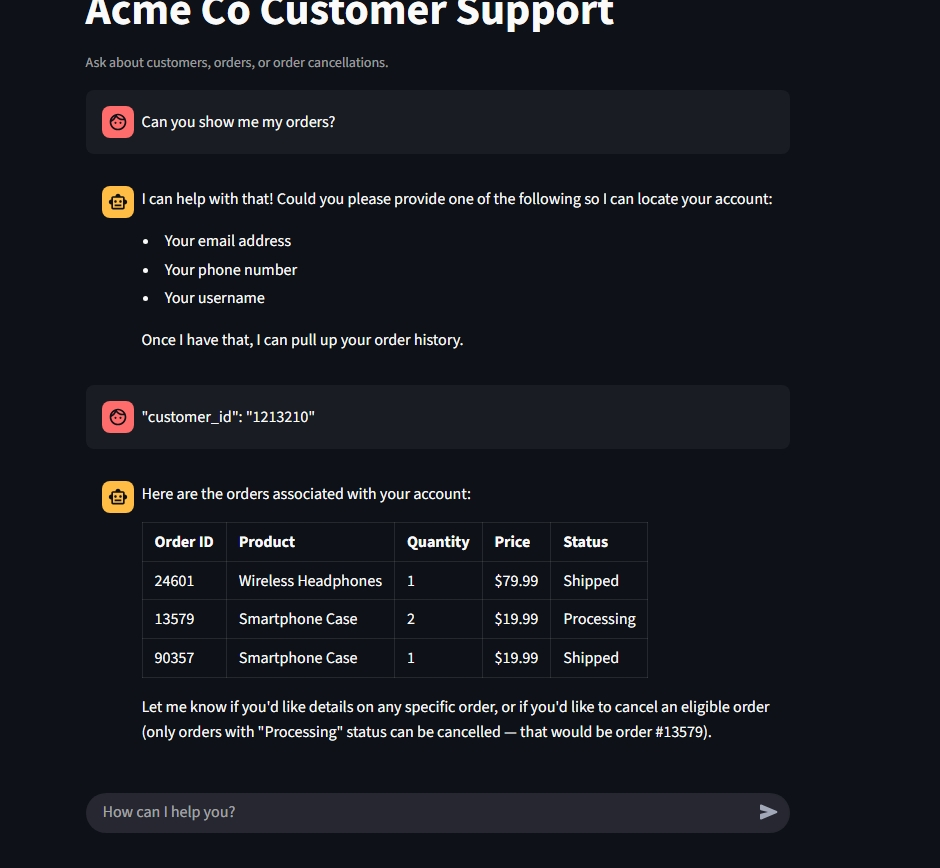

In [1]:
from IPython.display import Image
Image(filename='Screenshot_Tool_Use_Streamlit.jpeg') 

## Conclusion

This notebook shows that the **tool use** is able to connect Claude's ability to select actions with functions implemented by the application.  Once that loop is in place, the assistant can answer real-world questions more accurately and safely than a model acting alone.  

Briefly, the main ideas are:

- A tool definition describes what a tool does and what inputs it accepts.
- Claude can decide when a tool is needed and return a structured `tool_use`.
- Your application executes the actual Python function.
- The result is returned to Claude using `tool_result`.
- `stop_reason` tells the application whether Claude needs another tool call
  or has finished.
- The complete pattern is an iterative message loop.
- Good tool descriptions and input schemas make tool selection more reliable.

## Extra practice 

The best way to understand tool use is to extend  the fake database, yourself.  

### Challenge 1: Add a Shipping Tool

Add a new tool called: `get_shipping_status(order_id)` and return the shipping status of the order.

Your tasks:  

- Add shipping information to the fake database.  
- Define the tool schema.  
- Add the tool to tools.  
- Update process_tool_call().  
- Test the assistant with a shipping-related request.  

For example:

`"Where is my order 24601?"`


### Challenge 2 — Add a Refund Tool

Create: `process_refund(order_id)` 

Decide what business rules should apply.

For example:

- Can shipped orders be refunded?  
- Can cancelled orders be refunded?  
- What happens if the order does not exist?  
- What should the tool return when a refund is rejected?    
- Which orders are eligible?  
- What should happen when the order is not eligible?  
- What should the tool return?    

### Challenge 3 — Handle Multiple Tools

Create a request that requires more than one tool. For instance, give Claude a request such as:

`"Find Priya's orders and tell me which ones are still processing."`



### Challenge 4 — Handle Tool Errors

Test what happens when a tool cannot complete the requested operation.

Try cases such as:

- unknown customer  
- unknown order  
- invalid order ID  
- cancellation of an already shipped order  
- missing required information  